In [4]:
from plots import OptunaVisualizer
from evaluation import ClinicalTrialRunner
import os
import joblib

In [5]:
# ==========================================
# 1. PATH CONFIGURATION
# ==========================================
results_path = 'tuning_results/completed_studies.pkl'

# ==========================================
# 2. LOAD THE RESULTS
# ==========================================
if os.path.exists(results_path):
    # Load the big dictionary generated by the terminal script
    completed_studies = joblib.load(results_path)
    print(f" Successfully loaded optimization results from: {results_path}")
    
    # ------------------------------------------
    # 3. EXTRACT OPTIMAL THRESHOLDS
    # ------------------------------------------
    # pH Optimal Parameters
    best_ph_raw_drift = completed_studies['ph']['raw'].best_params['raw_drift_threshold']
    best_ph_agg_pers = completed_studies['ph']['agg'].best_params['agg_persistence']
    best_ph_agg_drift = completed_studies['ph']['agg'].best_params['agg_abs_drift']

    # Temperature Optimal Parameters
    best_temp_raw_drift = completed_studies['temp']['raw'].best_params['raw_drift_threshold']
    best_temp_agg_pers = completed_studies['temp']['agg'].best_params['agg_persistence']
    best_temp_agg_drift = completed_studies['temp']['agg'].best_params['agg_abs_drift']

    # Combined Optimal Parameters
    best_comb_raw_drift_ph = completed_studies['combined']['raw'].best_params['raw_drift_ph']
    best_comb_raw_drift_temp = completed_studies['combined']['raw'].best_params['raw_drift_temp']
    best_comb_agg_pers = completed_studies['combined']['agg'].best_params['agg_persistence']
    best_comb_agg_drift_ph = completed_studies['combined']['agg'].best_params['agg_abs_drift_ph']
    best_comb_agg_drift_temp = completed_studies['combined']['agg'].best_params['agg_abs_drift_temp']

    # ------------------------------------------
    # 4. PRINT SUMMARY TABLE
    # ------------------------------------------
    print("\n" + "="*30)
    print(" FINAL OPTIMIZED THRESHOLDS")
    print("="*30)
    print(f"pH Raw Drift:             {best_ph_raw_drift:.4f}")
    print(f"pH Agg Persistence:       {best_ph_agg_pers}")
    print(f"pH Agg Drift:             {best_ph_agg_drift:.4f}")
    print("-" * 30)
    print(f"Temp Raw Drift:           {best_temp_raw_drift:.4f}")
    print(f"Temp Agg Persistence:     {best_temp_agg_pers}")
    print(f"Temp Agg Drift:           {best_temp_agg_drift:.4f}")
    print("-" * 30)
    print(f"Combined Raw Drift (pH):  {best_comb_raw_drift_ph:.4f}")
    print(f"Combined Raw Drift (T):   {best_comb_raw_drift_temp:.4f}")
    print(f"Combined Agg Persistence: {best_comb_agg_pers}")
    print(f"Combined Agg Drift (pH):  {best_comb_agg_drift_ph:.4f}")
    print(f"Combined Agg Drift (T):   {best_comb_agg_drift_temp:.4f}")
    print("="*30 + "\n")

    # ------------------------------------------
    # 5. GENERATE VISUALIZATIONS
    # ------------------------------------------
    # opt_vis = OptunaVisualizer()

    # # pH Plots
    # opt_vis.plot_1d_raw_tuning(completed_studies['ph']['raw'], title_suffix="pH Raw")
    # opt_vis.plot_2d_agg_tuning(completed_studies['ph']['agg'], title_suffix="pH Aggregated")

    # # Temp Plots
    # opt_vis.plot_1d_raw_tuning(completed_studies['temp']['raw'], title_suffix="Temp Raw")
    # opt_vis.plot_2d_agg_tuning(completed_studies['temp']['agg'], title_suffix="Temp Aggregated")

    # # Combined Plots
    # opt_vis.plot_combined_raw_tuning(completed_studies['combined']['raw'], title_suffix="Combined Raw")
    # opt_vis.plot_combined_agg_tuning(completed_studies['combined']['agg'], title_suffix="Combined Aggregated")

else:
    print(f" ERROR: Results file not found at {results_path}")
    print("Please run 'python3 parameter_tuning.py' in your terminal first.")

 Successfully loaded optimization results from: tuning_results/completed_studies.pkl

 FINAL OPTIMIZED THRESHOLDS
pH Raw Drift:             1.5600
pH Agg Persistence:       1
pH Agg Drift:             0.0600
------------------------------
Temp Raw Drift:           5.0000
Temp Agg Persistence:     1
Temp Agg Drift:           0.6000
------------------------------
Combined Raw Drift (pH):  1.2100
Combined Raw Drift (T):   5.0000
Combined Agg Persistence: 2
Combined Agg Drift (pH):  0.0500
Combined Agg Drift (T):   0.5000



## pH Diseases


--- RUNNING TRIAL: STROKE_PH (Target Zones: [7]) ---
[STROKE_PH] Velocity: 1.0h | Random Onset: Hour 16.3 | Peak: Hour 17.3

--- Detection Results ---
Clinical Onset: Hour 16.29

[RAW STREAM ALERTS]
  --> ZONE 1 ALERT: [SPATIAL ERROR / LEAKAGE] at Hour 0.16 by Sensor
  --> ZONE 2 ALERT: [SPATIAL ERROR / LEAKAGE] at Hour 0.26 by Sensor
  --> ZONE 4 ALERT: [SPATIAL ERROR / LEAKAGE] at Hour 0.33 by Sensor
  --> ZONE 5 ALERT: [SPATIAL ERROR / LEAKAGE] at Hour 2.13 by Sensor
  --> ZONE 6 ALERT: [SPATIAL ERROR / LEAKAGE] at Hour 0.36 by Sensor
  --> ZONE 7 ALERT: (TRUE POSITIVE) at Hour 16.40 | Delay: 6.7 min
  --> ZONE 8 ALERT: [SPATIAL ERROR / LEAKAGE] at Hour 23.84 by Sensor
  --> ZONE 9 ALERT: [SPATIAL ERROR / LEAKAGE] at Hour 1.00 by Sensor
  --> ZONE 10 ALERT: [SPATIAL ERROR / LEAKAGE] at Hour 1.37 by Sensor
  --> ZONE 11 ALERT: [SPATIAL ERROR / LEAKAGE] at Hour 17.36 by Sensor
  --> ZONE 12 ALERT: [SPATIAL ERROR / LEAKAGE] at Hour 7.70 by Sensor
  --> ZONE 17 ALERT: [SPATIAL ERROR / 

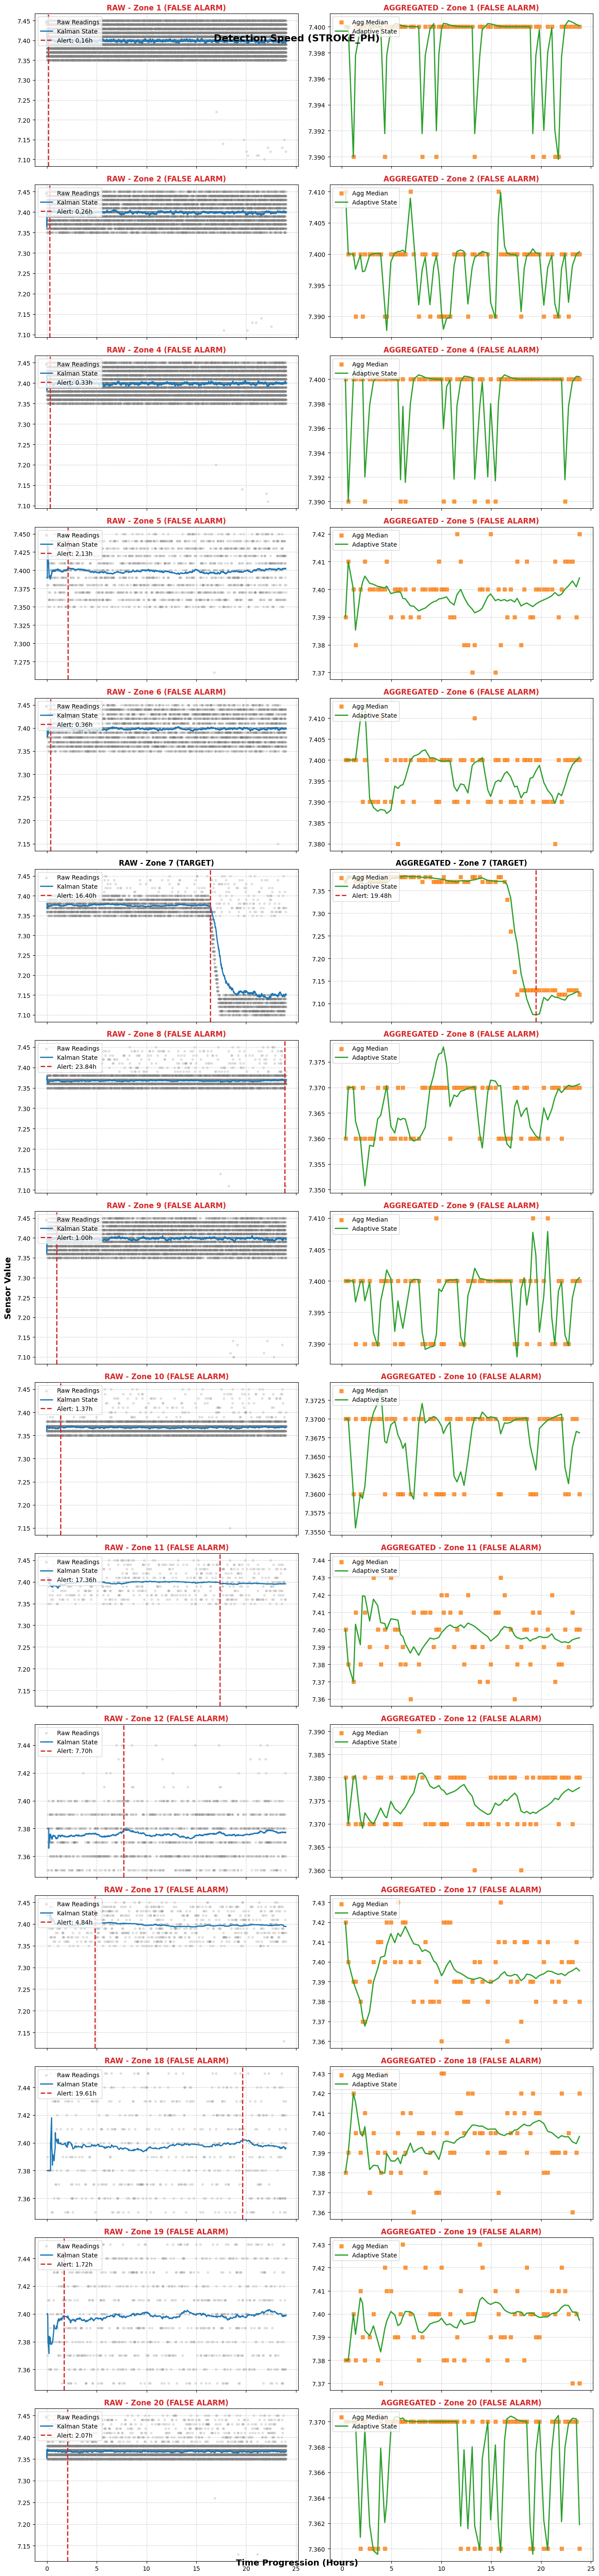

In [3]:
runner = ClinicalTrialRunner(alpha=0.3, beta=0.10)
runner.run_single_parameter_trial(
    disease_key='stroke_ph', 
    raw_drift=best_ph_raw_drift,        
    agg_pers=best_ph_agg_pers,          
    agg_drift=best_ph_agg_drift
)


--- RUNNING TRIAL: SYSTEMIC_ALKALOSIS_PH (Zone 1) ---
[SYSTEMIC_ALKALOSIS_PH] Velocity: 2.0h | Random Onset: Hour 8.7 | Peak: Hour 10.7

--- Running Anomaly Detection ---

--- Detection Results ---
Disease actually started at: Hour 8.69

[RAW STREAM ALERTS]
  --> ZONE 1 ALERT:
      - Flagged at Hour 9.02 by Sensor | Delay: 19.5 min
  --> ZONE 2 ALERT:
      - Flagged at Hour 9.08 by Sensor | Delay: 23.3 min
  --> ZONE 3 ALERT:
      - Flagged at Hour 9.07 by Sensor | Delay: 22.7 min
  --> ZONE 4 ALERT:
      - Flagged at Hour 8.97 by Sensor | Delay: 16.8 min
  --> ZONE 5 ALERT:
      - Flagged at Hour 9.32 by Sensor | Delay: 37.4 min
  --> ZONE 6 ALERT:
      - Flagged at Hour 9.14 by Sensor | Delay: 27.1 min
  --> ZONE 7 ALERT:
      - Flagged at Hour 9.21 by Sensor | Delay: 31.2 min
  --> ZONE 8 ALERT:
      - Flagged at Hour 9.13 by Sensor | Delay: 26.2 min
  --> ZONE 9 ALERT:
      - Flagged at Hour 9.05 by Sensor | Delay: 21.2 min
  --> ZONE 10 ALERT:
      - Flagged at Hour 9.1

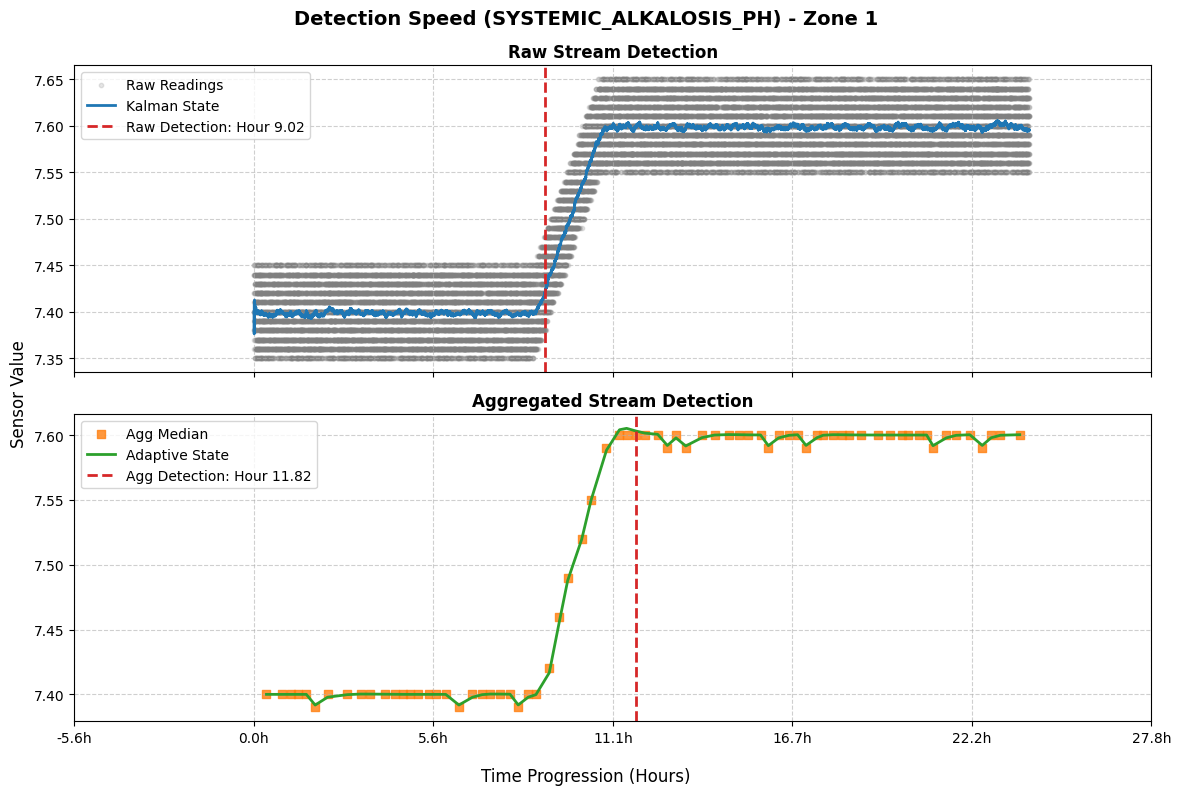

In [14]:
runner = ClinicalTrialRunner(alpha=0.3, beta=0.10)
runner.run_single_parameter_trial(
    disease_key='systemic_alkalosis_ph', 
    raw_drift=best_ph_raw_drift,        
    agg_pers=best_ph_agg_pers,          
    agg_drift=best_ph_agg_drift
)


--- RUNNING TRIAL: DKA_PH (Zone 1) ---
[DKA_PH] Velocity: 6.0h | Random Onset: Hour 10.2 | Peak: Hour 16.2

--- Running Anomaly Detection ---

--- Detection Results ---
Disease actually started at: Hour 10.20

[RAW STREAM ALERTS]
  --> ZONE 1 ALERT:
      - Flagged at Hour 10.73 by Sensor | Delay: 31.7 min
  --> ZONE 2 ALERT:
      - Flagged at Hour 10.82 by Sensor | Delay: 37.0 min
  --> ZONE 3 ALERT:
      - Flagged at Hour 10.89 by Sensor | Delay: 41.4 min
  --> ZONE 4 ALERT:
      - Flagged at Hour 10.63 by Sensor | Delay: 25.6 min
  --> ZONE 5 ALERT:
      - Flagged at Hour 11.35 by Sensor | Delay: 69.0 min

[AGGREGATED STREAM ALERTS]
  --> ZONE 1 ALERT:
      - Flagged at Hour 14.40 by Sensor | Delay: 251.8 min
  --> ZONE 2 ALERT:
      - Flagged at Hour 14.73 by Sensor | Delay: 271.3 min
  --> ZONE 3 ALERT:
      - Flagged at Hour 14.40 by Sensor | Delay: 251.8 min
  --> ZONE 4 ALERT:
      - Flagged at Hour 14.40 by Sensor | Delay: 251.8 min
  --> ZONE 5 ALERT:
      - Flagged

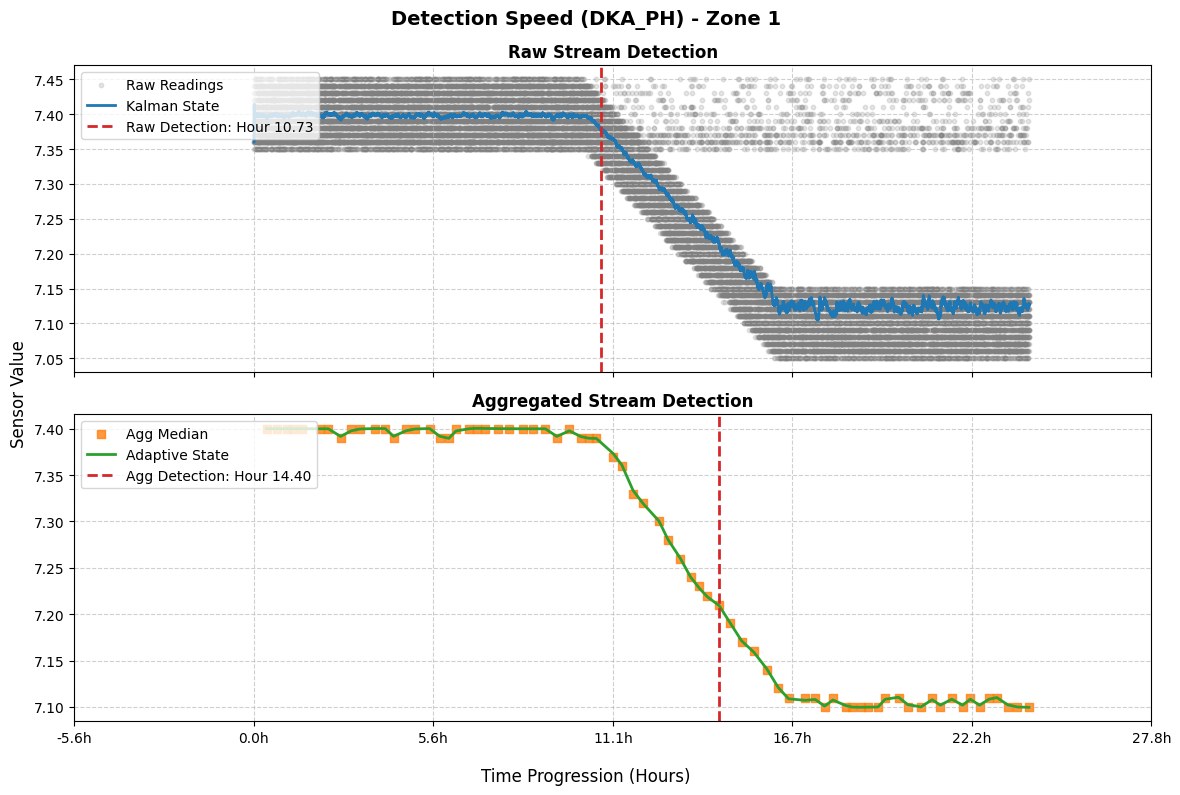

In [6]:
runner = ClinicalTrialRunner(alpha=0.3, beta=0.10)
runner.run_single_parameter_trial(
    disease_key='dka_ph', 
    raw_drift=best_ph_raw_drift,        
    agg_pers=best_ph_agg_pers,          
    agg_drift=best_ph_agg_drift
)


--- RUNNING TRIAL: NEC_PH (Zone 12) ---
[NEC_PH] Velocity: 4.0h | Random Onset: Hour 10.9 | Peak: Hour 14.9

--- Running Anomaly Detection ---

--- Detection Results ---
Disease actually started at: Hour 10.87

[RAW STREAM ALERTS]
  --> ZONE 12 ALERT:
      - Flagged at Hour 12.12 by Sensor | Delay: 75.5 min

[AGGREGATED STREAM ALERTS]
  --> ZONE 12 ALERT:
      - Flagged at Hour 16.01 by Sensor | Delay: 308.5 min

--- Generating Visualization ---


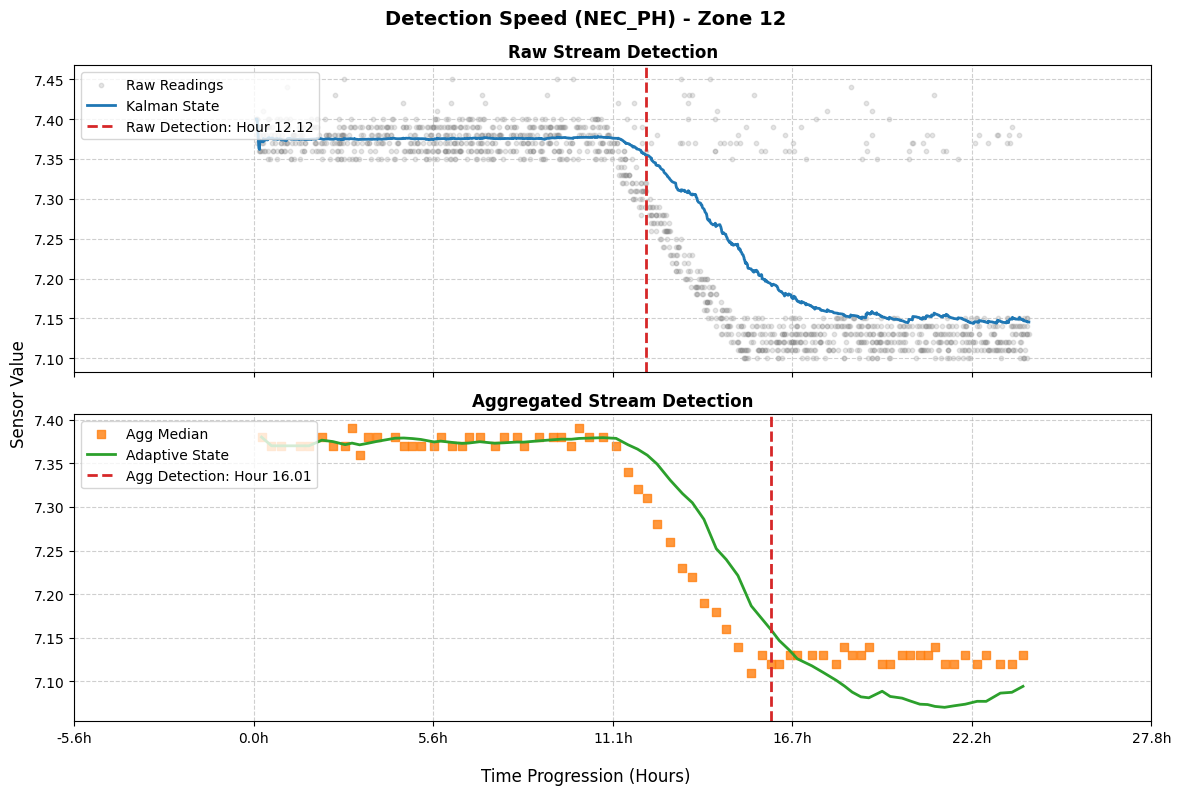

In [7]:
runner = ClinicalTrialRunner(alpha=0.3, beta=0.10)
runner.run_single_parameter_trial(
    disease_key='nec_ph', 
    raw_drift=best_ph_raw_drift,        
    agg_pers=best_ph_agg_pers,          
    agg_drift=best_ph_agg_drift
)


--- RUNNING TRIAL: RTA_PH (Zone 16) ---
[RTA_PH] Velocity: 12.0h | Random Onset: Hour 5.7 | Peak: Hour 17.7

--- Running Anomaly Detection ---

--- Detection Results ---
Disease actually started at: Hour 5.66

[RAW STREAM ALERTS]
  --> ZONE 16 ALERT:
      - Flagged at Hour 11.19 by Sensor | Delay: 331.8 min

[AGGREGATED STREAM ALERTS]
  --> ZONE 16 ALERT:
      - Flagged at Hour 19.78 by Sensor | Delay: 846.9 min

--- Generating Visualization ---


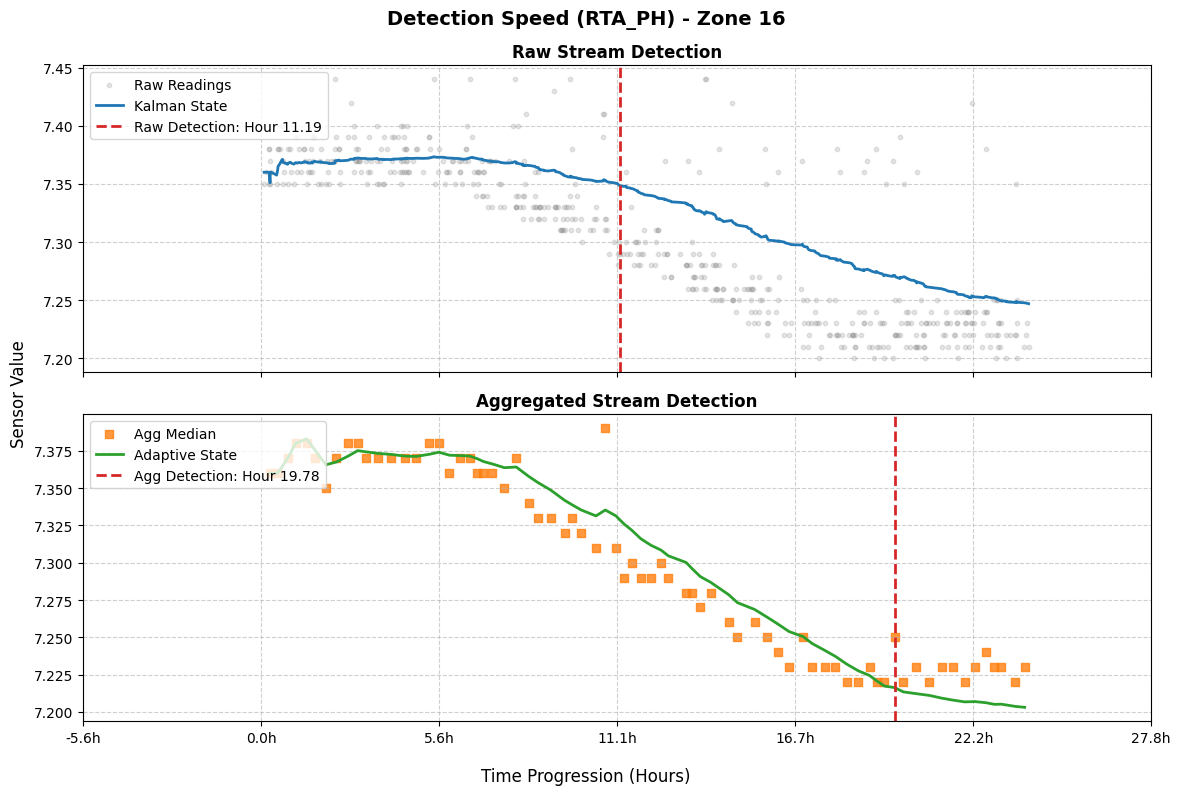

In [8]:
runner = ClinicalTrialRunner(alpha=0.3, beta=0.10)
runner.run_single_parameter_trial(
    disease_key='rta_ph', 
    raw_drift=best_ph_raw_drift,        
    agg_pers=best_ph_agg_pers,          
    agg_drift=best_ph_agg_drift
)

## Temperature Diseases


--- RUNNING TRIAL: MENINGITIS_TEMP (Target Zone 8) ---
[MENINGITIS_TEMP] Velocity: 3.0h | Random Onset: Hour 9.6 | Peak: Hour 12.6

--- Detection Results ---
Clinical Onset: Hour 9.64

[RAW STREAM ALERTS]
  --> ZONE 8 ALERT: (TRUE POSITIVE) at Hour 1.00 | FP/Early Detection (518.6 min early)
  --> ZONE 14 ALERT: [SPATIAL ERROR / LEAKAGE] at Hour 7.36 by Sensor
  --> ZONE 18 ALERT: [SPATIAL ERROR / LEAKAGE] at Hour 18.16 by Sensor
  --> ZONE 19 ALERT: [SPATIAL ERROR / LEAKAGE] at Hour 21.94 by Sensor
  --> ZONE 20 ALERT: [SPATIAL ERROR / LEAKAGE] at Hour 0.47 by Sensor

[AGGREGATED STREAM ALERTS]
  --> ZONE 8 ALERT: (TRUE POSITIVE) at Hour 12.29 | Delay: 158.9 min


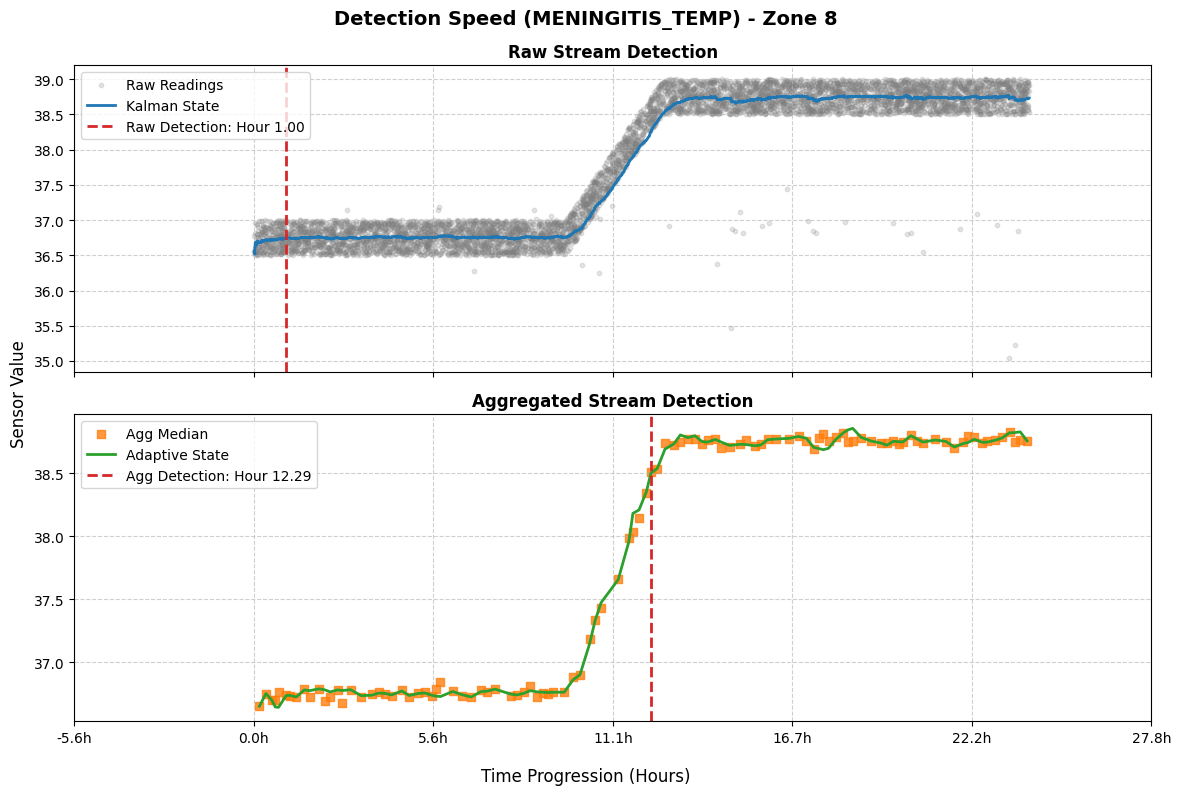

In [3]:
runner = ClinicalTrialRunner(alpha=0.3, beta=0.01)
runner.run_single_parameter_trial(
    disease_key='meningitis_temp', 
    raw_drift=best_temp_raw_drift,       
    agg_pers=best_temp_agg_pers,          
    agg_drift=best_temp_agg_drift       
)


--- RUNNING TRIAL: SYSTEMIC_FEVER_TEMP (Zone 1) ---
[SYSTEMIC_FEVER_TEMP] Velocity: 4.0h | Random Onset: Hour 16.4 | Peak: Hour 20.4

--- Running Anomaly Detection ---

--- Detection Results ---
Disease actually started at: Hour 16.41

[RAW STREAM ALERTS]
  --> ZONE 1 ALERT:
      - Flagged at Hour 16.57 by Sensor | Delay: 9.8 min
  --> ZONE 2 ALERT:
      - Flagged at Hour 16.65 by Sensor | Delay: 14.5 min
  --> ZONE 3 ALERT:
      - Flagged at Hour 16.62 by Sensor | Delay: 12.8 min
  --> ZONE 4 ALERT:
      - Flagged at Hour 16.64 by Sensor | Delay: 13.9 min
  --> ZONE 5 ALERT:
      - Flagged at Hour 16.94 by Sensor | Delay: 32.2 min
  --> ZONE 6 ALERT:
      - Flagged at Hour 16.73 by Sensor | Delay: 19.6 min
  --> ZONE 7 ALERT:
      - Flagged at Hour 16.84 by Sensor | Delay: 26.1 min
  --> ZONE 8 ALERT:
      - Flagged at Hour 2.37 by Sensor | False Positive (842.3 min early)
  --> ZONE 9 ALERT:
      - Flagged at Hour 16.64 by Sensor | Delay: 14.2 min
  --> ZONE 10 ALERT:
     

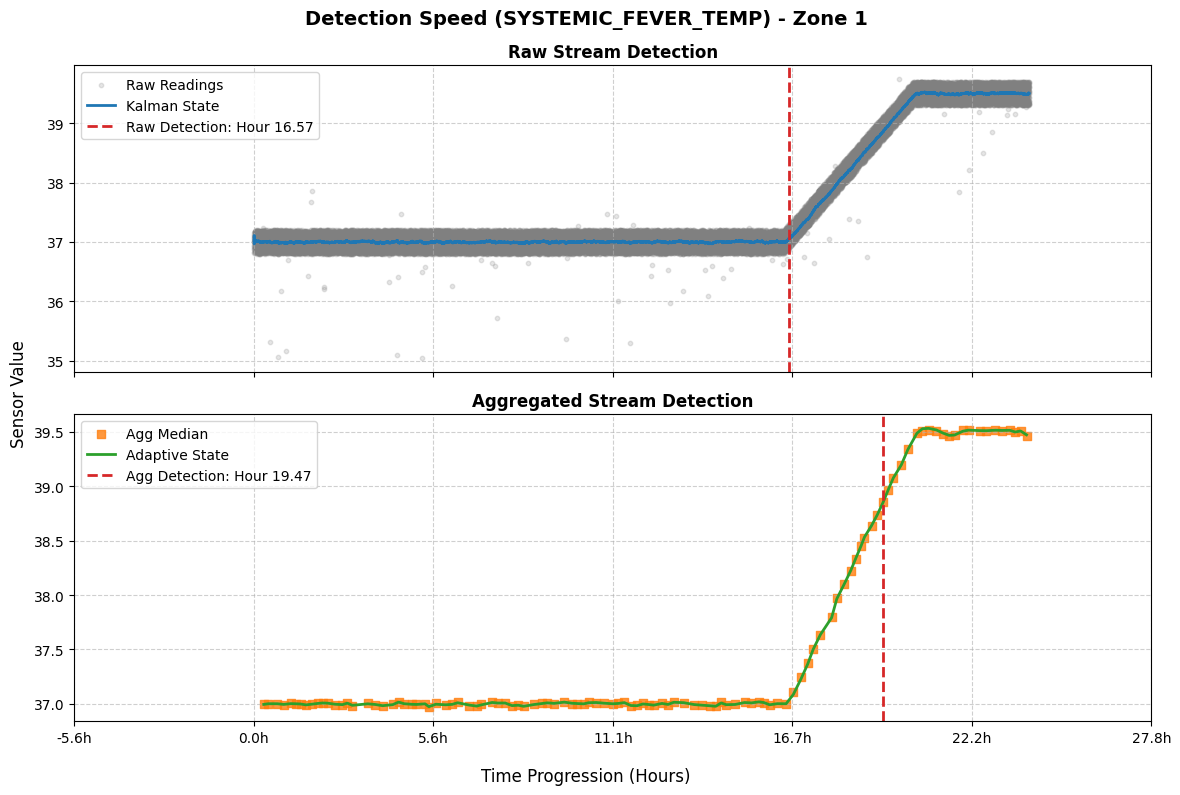

In [9]:
runner = ClinicalTrialRunner(alpha=0.3, beta=0.01)
runner.run_single_parameter_trial(
    disease_key='systemic_fever_temp', 
    raw_drift=best_temp_raw_drift,       
    agg_pers=best_temp_agg_pers,          
    agg_drift=best_temp_agg_drift       
)


--- RUNNING TRIAL: ENDOCARDITIS_TEMP (Zone 1) ---
[ENDOCARDITIS_TEMP] Velocity: 12.0h | Random Onset: Hour 1.2 | Peak: Hour 13.2

--- Running Anomaly Detection ---

--- Detection Results ---
Disease actually started at: Hour 1.25

[RAW STREAM ALERTS]
  --> ZONE 1 ALERT:
      - Flagged at Hour 1.67 by Sensor | Delay: 25.2 min
  --> ZONE 2 ALERT:
      - Flagged at Hour 1.91 by Sensor | Delay: 39.5 min
  --> ZONE 3 ALERT:
      - Flagged at Hour 1.85 by Sensor | Delay: 36.0 min
  --> ZONE 8 ALERT:
      - Flagged at Hour 12.79 by Sensor | Delay: 692.6 min
  --> ZONE 15 ALERT:
      - Flagged at Hour 6.72 by Sensor | Delay: 328.5 min
  --> ZONE 20 ALERT:
      - Flagged at Hour 0.14 by Sensor | False Positive (66.8 min early)

[AGGREGATED STREAM ALERTS]
  --> ZONE 2 ALERT:
      - Flagged at Hour 13.99 by Sensor | Delay: 764.6 min
  --> ZONE 3 ALERT:
      - Flagged at Hour 15.14 by Sensor | Delay: 833.1 min

--- Generating Visualization ---


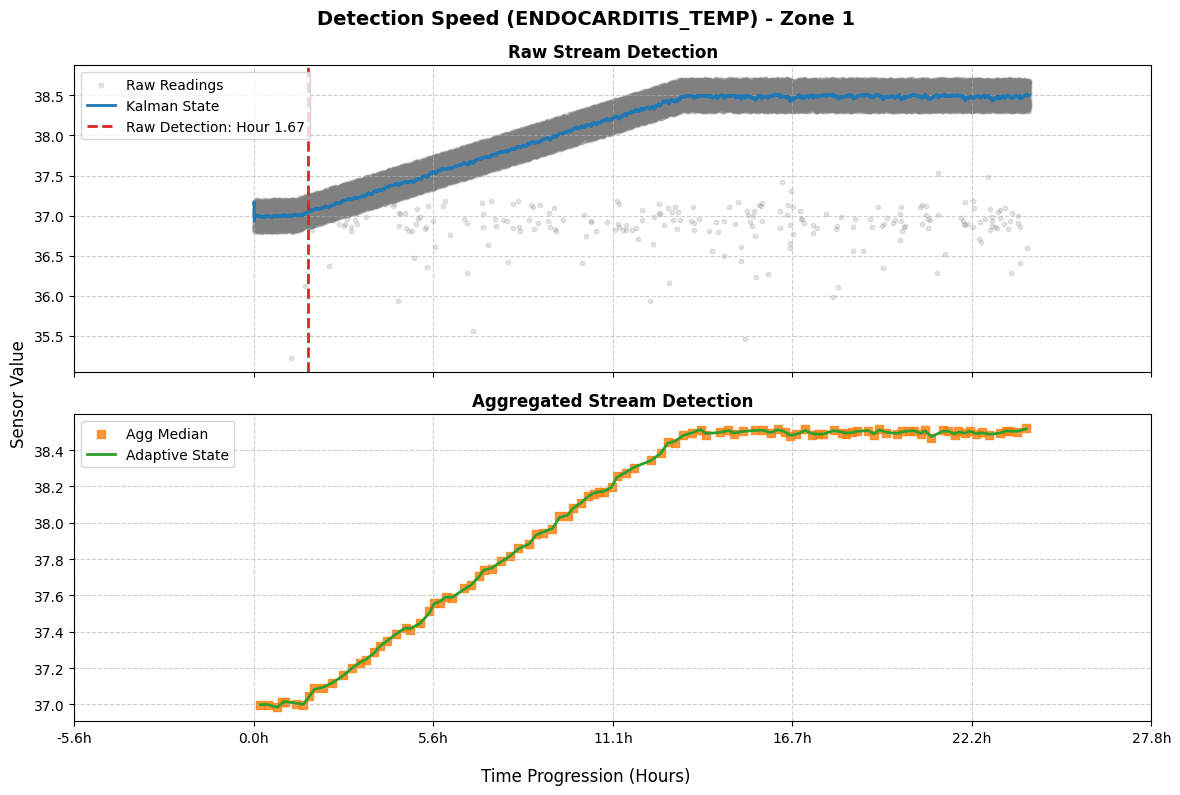

In [10]:
runner = ClinicalTrialRunner(alpha=0.3, beta=0.01)
runner.run_single_parameter_trial(
    disease_key='endocarditis_temp', 
    raw_drift=best_temp_raw_drift,       
    agg_pers=best_temp_agg_pers,          
    agg_drift=best_temp_agg_drift       
)


--- RUNNING TRIAL: ARTERIAL_OCCLUSION_TEMP (Zone 19) ---
[ARTERIAL_OCCLUSION_TEMP] Velocity: 1.5h | Random Onset: Hour 1.0 | Peak: Hour 2.5

--- Running Anomaly Detection ---

--- Detection Results ---
Disease actually started at: Hour 0.97

[RAW STREAM ALERTS]
  --> ZONE 1 ALERT:
      - Flagged at Hour 0.53 by Sensor | False Positive (26.2 min early)
  --> ZONE 2 ALERT:
      - Flagged at Hour 16.63 by Sensor | Delay: 939.8 min
  --> ZONE 3 ALERT:
      - Flagged at Hour 20.03 by Sensor | Delay: 1143.6 min
  --> ZONE 4 ALERT:
      - Flagged at Hour 5.15 by Sensor | Delay: 251.1 min
  --> ZONE 5 ALERT:
      - Flagged at Hour 22.45 by Sensor | Delay: 1289.2 min
  --> ZONE 7 ALERT:
      - Flagged at Hour 11.97 by Sensor | Delay: 660.3 min
  --> ZONE 8 ALERT:
      - Flagged at Hour 20.60 by Sensor | Delay: 1177.9 min
  --> ZONE 9 ALERT:
      - Flagged at Hour 6.36 by Sensor | Delay: 323.7 min
  --> ZONE 12 ALERT:
      - Flagged at Hour 20.23 by Sensor | Delay: 1155.7 min
  --> ZON

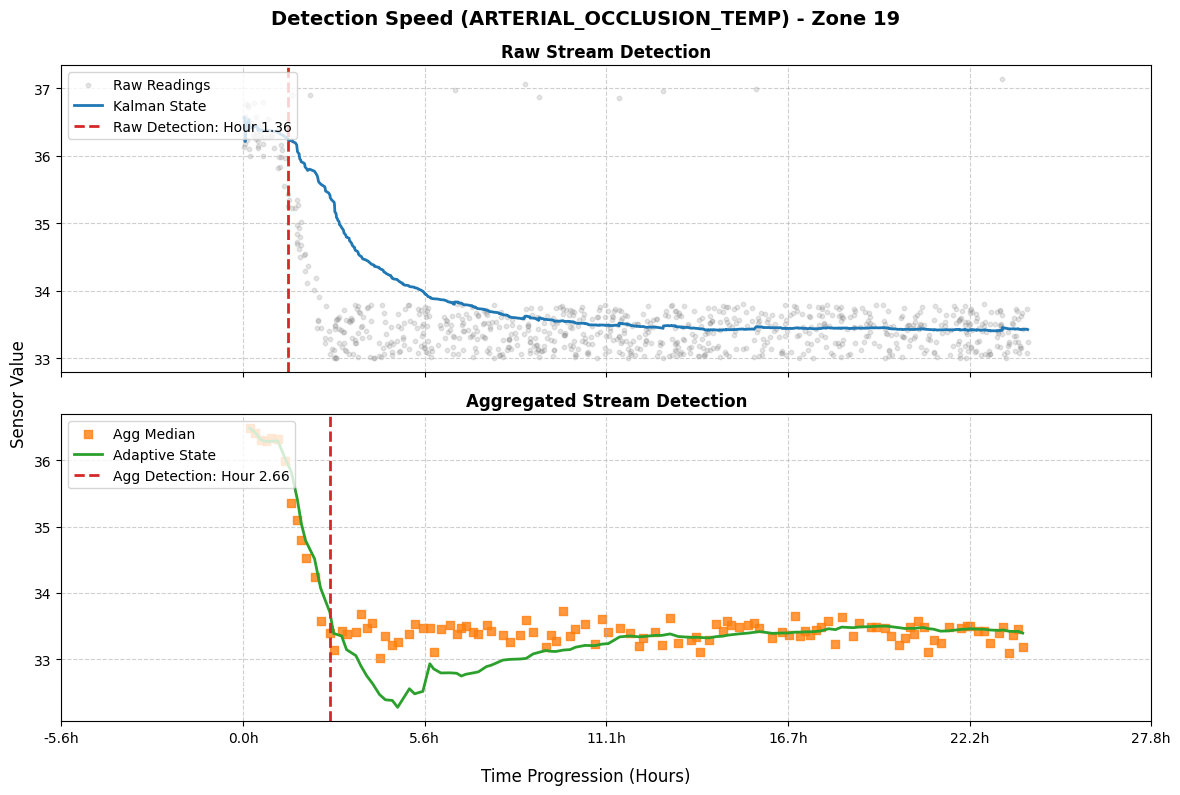

In [11]:
runner = ClinicalTrialRunner(alpha=0.3, beta=0.01)
runner.run_single_parameter_trial(
    disease_key='arterial_occlusion_temp', 
    raw_drift=best_temp_raw_drift,       
    agg_pers=best_temp_agg_pers,          
    agg_drift=best_temp_agg_drift       
)


--- RUNNING TRIAL: DVT_TEMP (Target Zone 19) ---
[DVT_TEMP] Velocity: 8.0h | Random Onset: Hour 4.2 | Peak: Hour 12.2

--- Detection Results ---
Clinical Onset: Hour 4.16

[RAW STREAM ALERTS]
  --> ZONE 1 ALERT: [SPATIAL ERROR / LEAKAGE] at Hour 12.94 by Sensor
  --> ZONE 19 ALERT: (TRUE POSITIVE) at Hour 4.48 | Delay: 19.0 min
  --> ZONE 20 ALERT: [SPATIAL ERROR / LEAKAGE] at Hour 0.77 by Sensor

[AGGREGATED STREAM ALERTS]
  --> ZONE 19 ALERT: (TRUE POSITIVE) at Hour 11.24 | Delay: 424.8 min


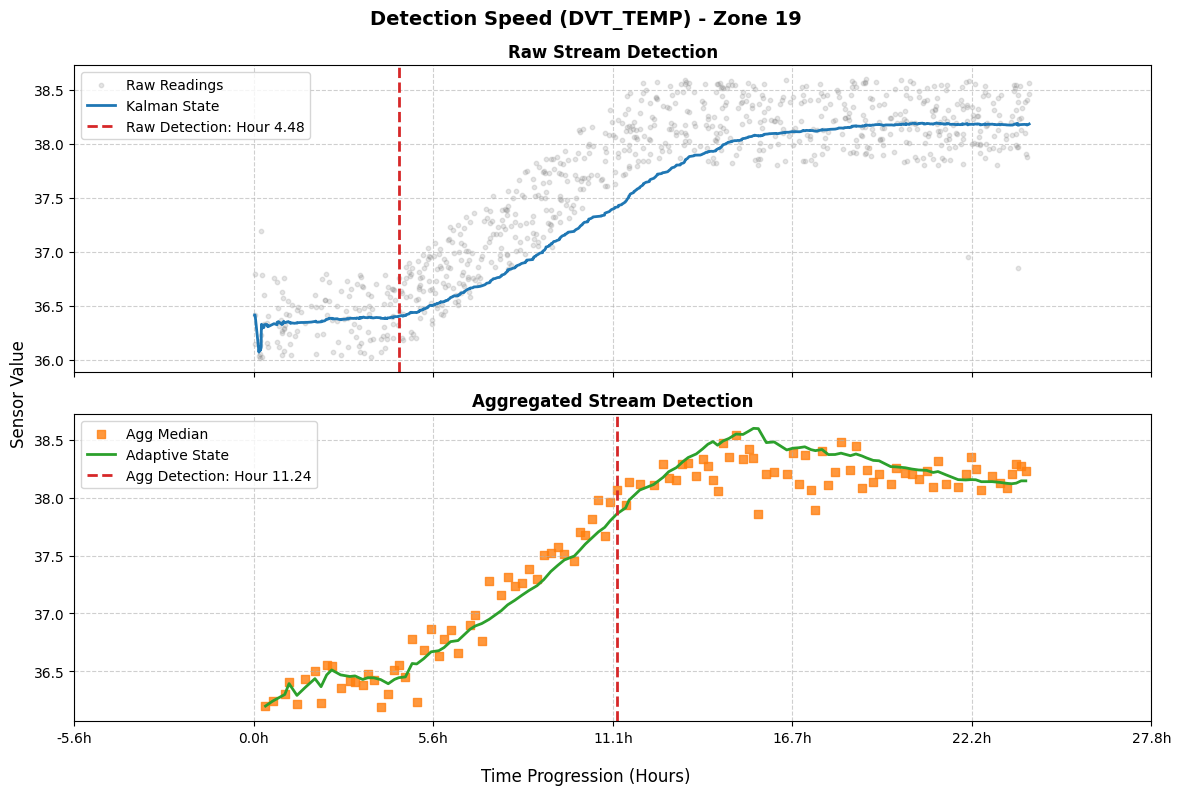

In [4]:
runner = ClinicalTrialRunner(alpha=0.3, beta=0.01)
runner.run_single_parameter_trial(
    disease_key='dvt_temp', 
    raw_drift=best_temp_raw_drift,       
    agg_pers=best_temp_agg_pers,          
    agg_drift=best_temp_agg_drift       
)

## Combined pH & Temperature Diseases


--- RUNNING COMBINED TRIAL: SEPTIC_SHOCK_COMBINED (Zone 1) ---
[SEPTIC_SHOCK_COMBINED] Velocity: 3.0h | Random Onset: Hour 17.5 | Peak: Hour 20.5

--- Running Combined Anomaly Detection ---

--- Detection Results ---
Disease actually started at: Hour 17.51

[RAW COMBINED STREAM ALERTS]
  --> ZONE 1 ALERT:
      - Flagged at Hour 0.54 by Temp | False Positive (1018.1 min early)
  --> ZONE 2 ALERT:
      - Flagged at Hour 17.69 by Temp | Delay: 11.0 min
  --> ZONE 3 ALERT:
      - Flagged at Hour 0.23 by Temp | False Positive (1036.7 min early)
  --> ZONE 4 ALERT:
      - Flagged at Hour 0.60 by Temp | False Positive (1014.8 min early)
  --> ZONE 5 ALERT:
      - Flagged at Hour 17.84 by Temp | Delay: 19.9 min
  --> ZONE 6 ALERT:
      - Flagged at Hour 1.00 by Temp | False Positive (990.7 min early)
  --> ZONE 7 ALERT:
      - Flagged at Hour 0.70 by Temp | False Positive (1008.6 min early)
  --> ZONE 8 ALERT:
      - Flagged at Hour 3.64 by Temp | False Positive (832.0 min early)
  --

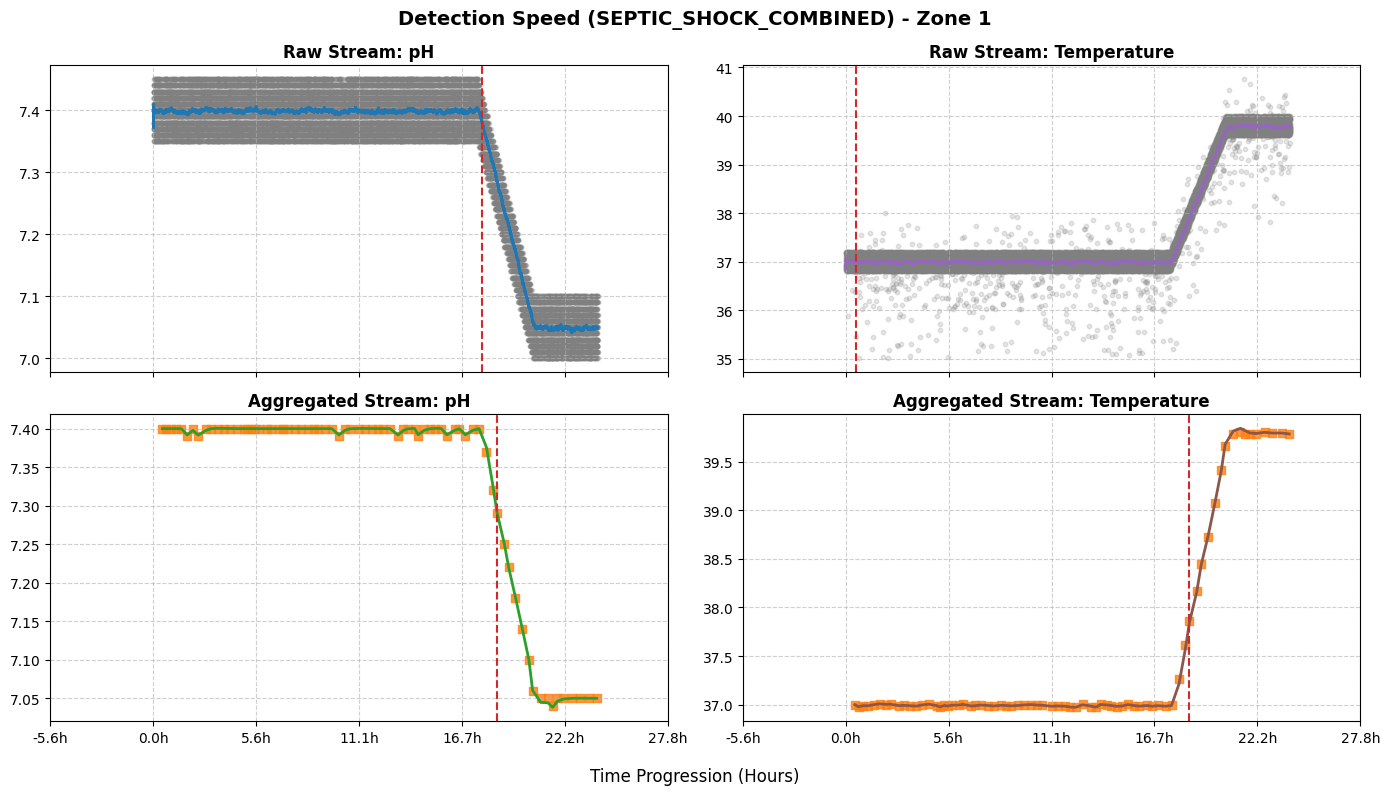

In [11]:
runner = ClinicalTrialRunner(alpha=0.3, beta=0.1)
runner.run_combined_parameter_trial(
    disease_key='septic_shock_combined',
    raw_drift_ph=best_comb_raw_drift_ph,     
    raw_drift_temp=best_comb_raw_drift_temp,   
    agg_pers=best_comb_agg_pers,           
    agg_drift_ph=best_comb_agg_drift_ph,    
    agg_drift_temp=best_comb_agg_drift_temp
)


--- RUNNING COMBINED TRIAL: MALIGNANT_HYPERTHERMIA_COMBINED (Zone 1) ---
[MALIGNANT_HYPERTHERMIA_COMBINED] Velocity: 0.5h | Random Onset: Hour 7.6 | Peak: Hour 8.1

--- Running Combined Anomaly Detection ---

--- Detection Results ---
Disease actually started at: Hour 7.61

[RAW COMBINED STREAM ALERTS]
  --> ZONE 1 ALERT:
      - Flagged at Hour 7.64 by Temp | Delay: 2.0 min
  --> ZONE 2 ALERT:
      - Flagged at Hour 7.64 by Temp | Delay: 1.8 min
  --> ZONE 3 ALERT:
      - Flagged at Hour 7.66 by Temp | Delay: 3.3 min
  --> ZONE 4 ALERT:
      - Flagged at Hour 3.19 by Temp | False Positive (265.1 min early)
  --> ZONE 5 ALERT:
      - Flagged at Hour 7.73 by Temp | Delay: 7.3 min
  --> ZONE 6 ALERT:
      - Flagged at Hour 0.77 by Temp | False Positive (410.1 min early)
  --> ZONE 7 ALERT:
      - Flagged at Hour 8.25 by Temp | Delay: 38.2 min
  --> ZONE 8 ALERT:
      - Flagged at Hour 7.73 by Temp | Delay: 7.5 min
  --> ZONE 9 ALERT:
      - Flagged at Hour 2.23 by Temp | False P

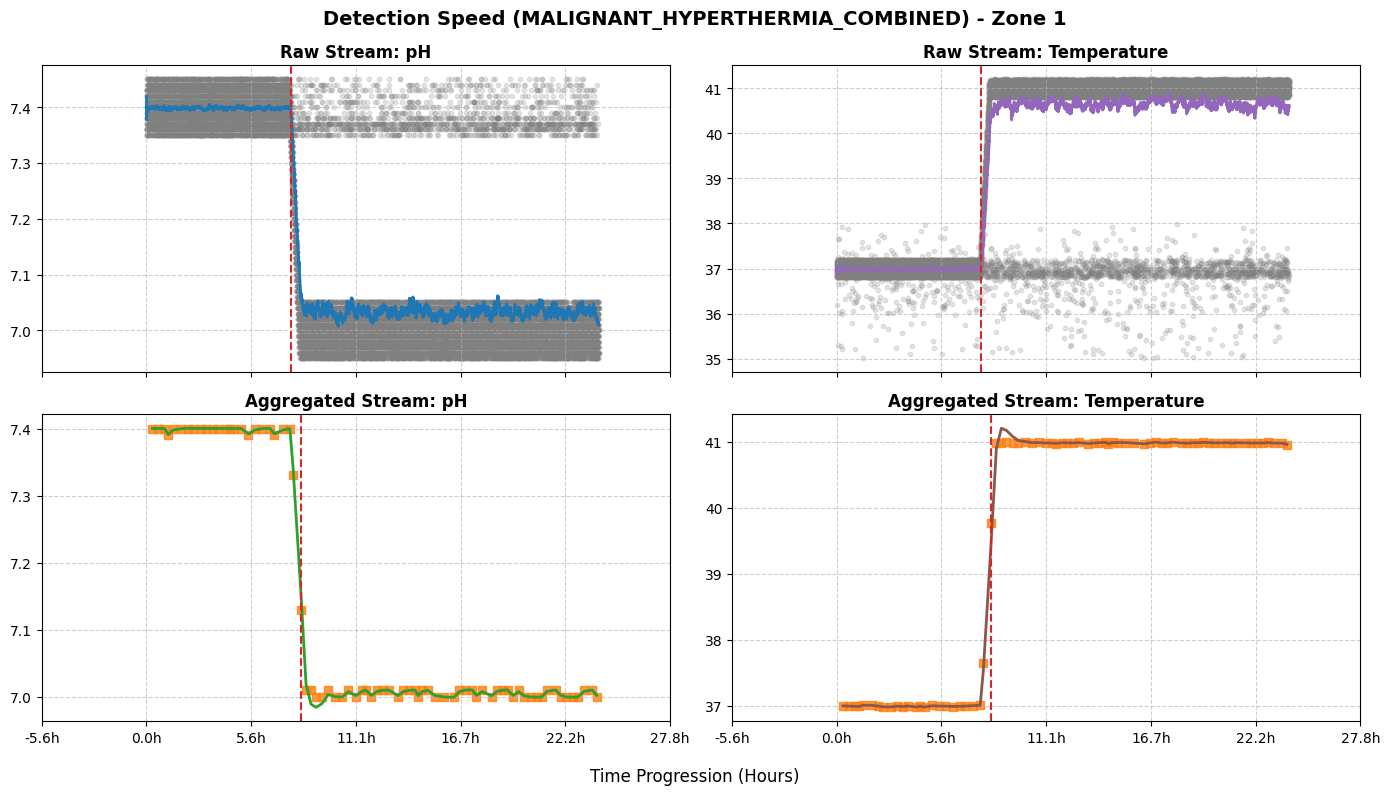

In [12]:
runner = ClinicalTrialRunner(alpha=0.3, beta=0.1)
runner.run_combined_parameter_trial(
    disease_key='malignant_hyperthermia_combined',
    raw_drift_ph=best_comb_raw_drift_ph,     
    raw_drift_temp=best_comb_raw_drift_temp,   
    agg_pers=best_comb_agg_pers,           
    agg_drift_ph=best_comb_agg_drift_ph,    
    agg_drift_temp=best_comb_agg_drift_temp
)


--- RUNNING COMBINED TRIAL: ISCHEMIC_BOWEL_COMBINED (Zone 12) ---
[ISCHEMIC_BOWEL_COMBINED] Velocity: 4.0h | Random Onset: Hour 2.6 | Peak: Hour 6.6

--- Running Combined Anomaly Detection ---

--- Detection Results ---
Disease actually started at: Hour 2.58

[RAW COMBINED STREAM ALERTS]
  --> ZONE 1 ALERT:
      - Flagged at Hour 3.11 by Temp | Delay: 32.1 min
  --> ZONE 2 ALERT:
      - Flagged at Hour 5.83 by Temp | Delay: 195.2 min
  --> ZONE 3 ALERT:
      - Flagged at Hour 7.70 by Temp | Delay: 307.1 min
  --> ZONE 4 ALERT:
      - Flagged at Hour 8.31 by Temp | Delay: 343.8 min
  --> ZONE 5 ALERT:
      - Flagged at Hour 12.65 by Temp | Delay: 604.1 min
  --> ZONE 6 ALERT:
      - Flagged at Hour 19.30 by Temp | Delay: 1003.0 min
  --> ZONE 7 ALERT:
      - Flagged at Hour 5.27 by Temp | Delay: 161.5 min
  --> ZONE 8 ALERT:
      - Flagged at Hour 4.67 by Temp | Delay: 125.3 min
  --> ZONE 10 ALERT:
      - Flagged at Hour 11.75 by Temp | Delay: 550.4 min
  --> ZONE 12 ALERT:
 

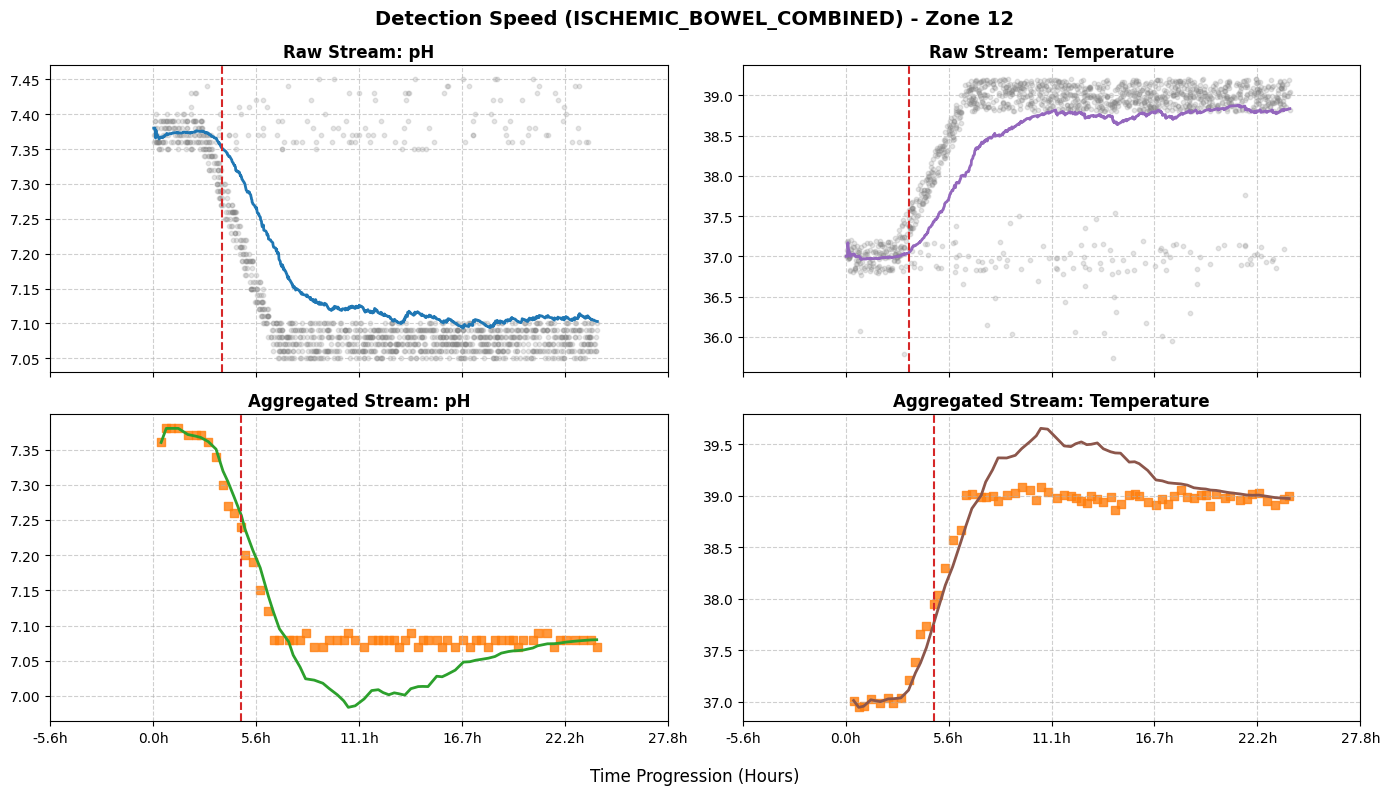

In [13]:
runner = ClinicalTrialRunner(alpha=0.3, beta=0.1)
runner.run_combined_parameter_trial(
    disease_key='ischemic_bowel_combined',
    raw_drift_ph=best_comb_raw_drift_ph,     
    raw_drift_temp=best_comb_raw_drift_temp,   
    agg_pers=best_comb_agg_pers,           
    agg_drift_ph=best_comb_agg_drift_ph,    
    agg_drift_temp=best_comb_agg_drift_temp
)


--- RUNNING COMBINED TRIAL: PYELO_COMBINED (Zone 16) ---
[PYELO_COMBINED] Velocity: 6.0h | Random Onset: Hour 5.4 | Peak: Hour 11.4

--- Running Combined Anomaly Detection ---

--- Detection Results ---
Disease actually started at: Hour 5.43

[RAW COMBINED STREAM ALERTS]
  --> ZONE 1 ALERT:
      - Flagged at Hour 15.20 by Temp | Delay: 586.3 min
  --> ZONE 2 ALERT:
      - Flagged at Hour 16.51 by Temp | Delay: 664.8 min
  --> ZONE 3 ALERT:
      - Flagged at Hour 15.96 by Temp | Delay: 632.0 min
  --> ZONE 4 ALERT:
      - Flagged at Hour 1.64 by Temp | False Positive (227.3 min early)
  --> ZONE 6 ALERT:
      - Flagged at Hour 1.38 by Temp | False Positive (242.8 min early)
  --> ZONE 7 ALERT:
      - Flagged at Hour 4.55 by Temp | False Positive (52.4 min early)
  --> ZONE 8 ALERT:
      - Flagged at Hour 8.87 by Temp | Delay: 206.5 min
  --> ZONE 9 ALERT:
      - Flagged at Hour 12.99 by Temp | Delay: 454.2 min
  --> ZONE 10 ALERT:
      - Flagged at Hour 10.03 by Temp | Delay: 

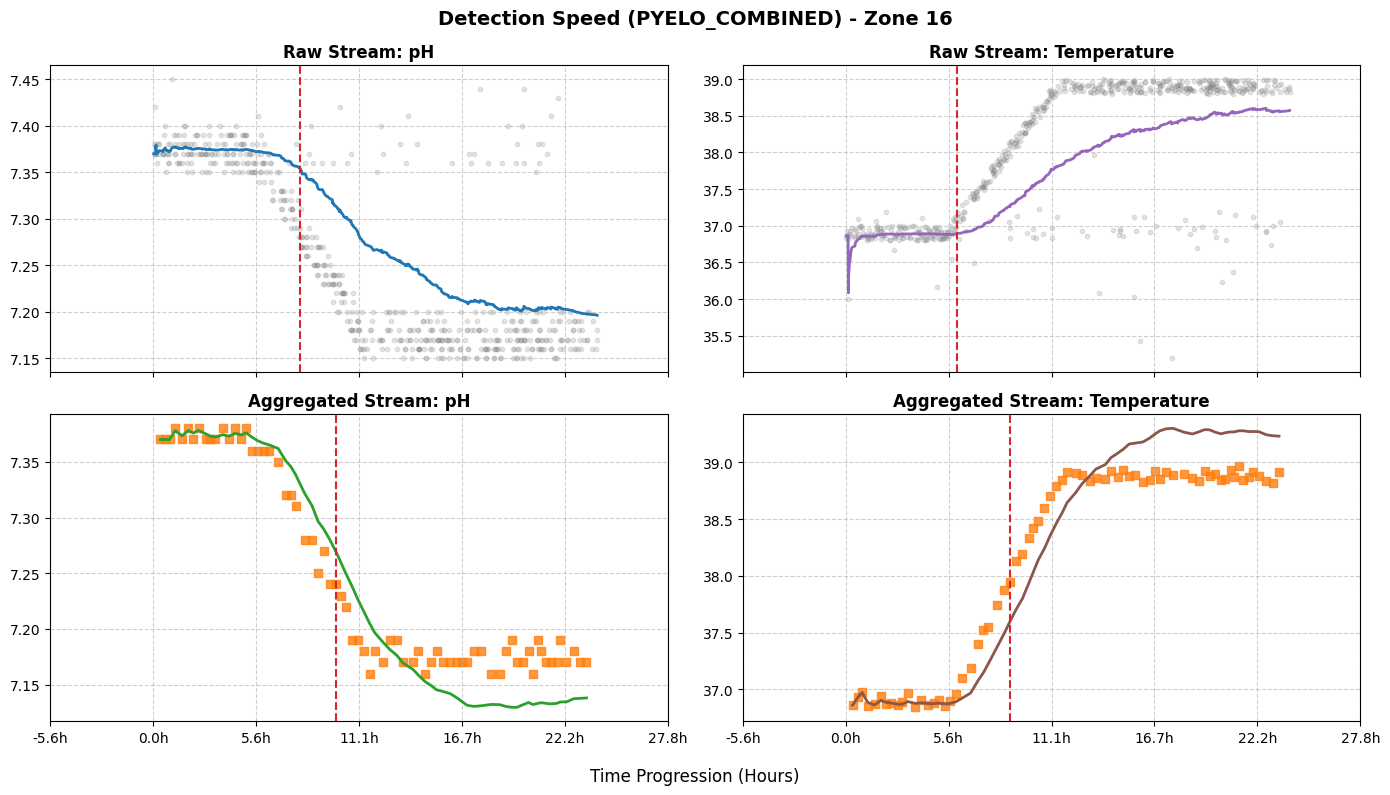

In [14]:
runner = ClinicalTrialRunner(alpha=0.3, beta=0.1)
runner.run_combined_parameter_trial(
    disease_key='pyelo_combined',
    raw_drift_ph=best_comb_raw_drift_ph,     
    raw_drift_temp=best_comb_raw_drift_temp,   
    agg_pers=best_comb_agg_pers,           
    agg_drift_ph=best_comb_agg_drift_ph,    
    agg_drift_temp=best_comb_agg_drift_temp
)


--- RUNNING COMBINED TRIAL: ISCHEMIA_COMBINED (Zone 19) ---
[ISCHEMIA_COMBINED] Velocity: 2.0h | Random Onset: Hour 2.1 | Peak: Hour 4.1

--- Running Combined Anomaly Detection ---

--- Detection Results ---
Disease actually started at: Hour 2.14

[RAW COMBINED STREAM ALERTS]
  --> ZONE 1 ALERT:
      - Flagged at Hour 0.68 by Temp | False Positive (87.6 min early)
  --> ZONE 2 ALERT:
      - Flagged at Hour 0.51 by Temp | False Positive (97.8 min early)
  --> ZONE 3 ALERT:
      - Flagged at Hour 4.19 by Temp | Delay: 123.0 min
  --> ZONE 4 ALERT:
      - Flagged at Hour 0.35 by Temp | False Positive (107.3 min early)
  --> ZONE 5 ALERT:
      - Flagged at Hour 4.04 by Temp | Delay: 114.3 min
  --> ZONE 6 ALERT:
      - Flagged at Hour 3.65 by Temp | Delay: 90.6 min
  --> ZONE 7 ALERT:
      - Flagged at Hour 2.92 by Temp | Delay: 46.6 min
  --> ZONE 8 ALERT:
      - Flagged at Hour 1.35 by Temp | False Positive (47.3 min early)
  --> ZONE 9 ALERT:
      - Flagged at Hour 3.44 by Tem

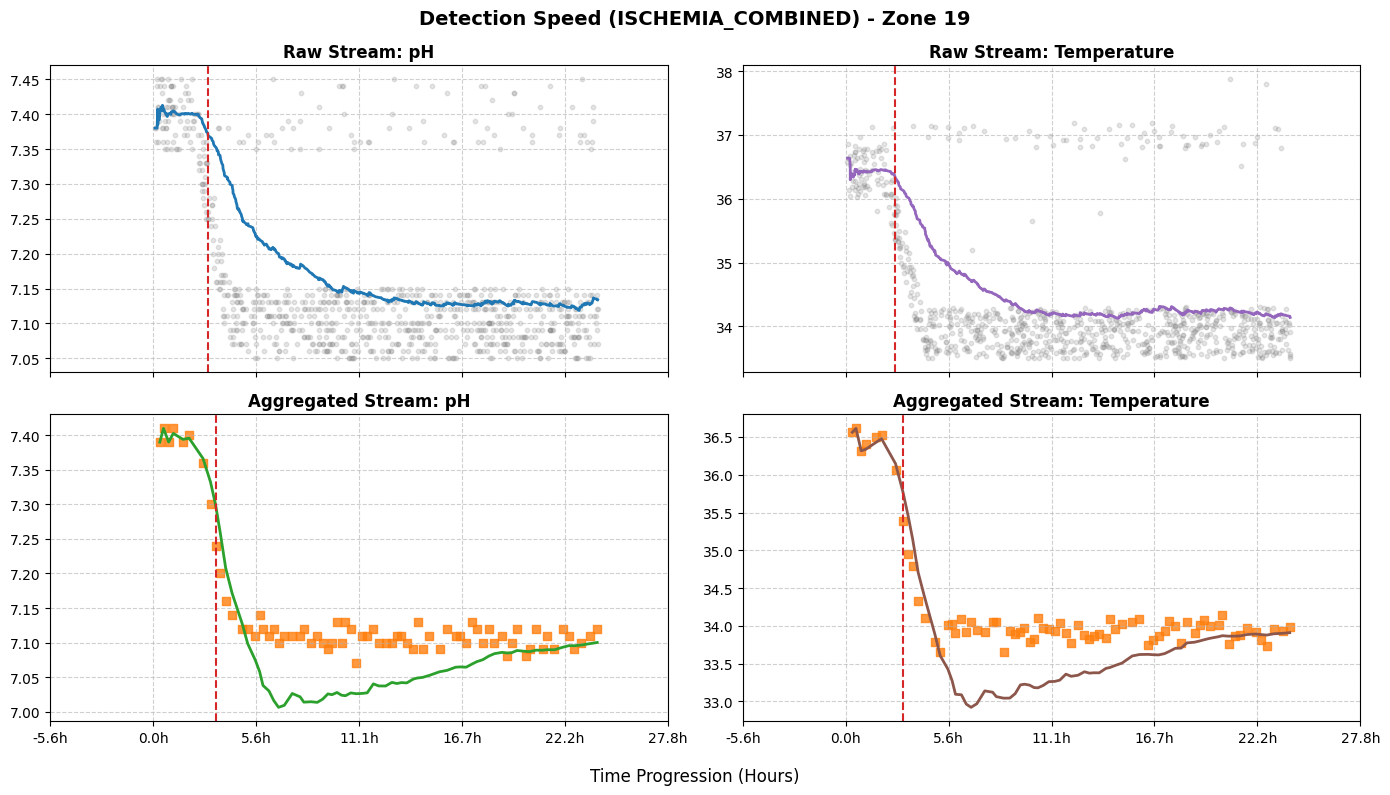

In [15]:
runner = ClinicalTrialRunner(alpha=0.3, beta=0.1)
runner.run_combined_parameter_trial(
    disease_key='ischemia_combined',
    raw_drift_ph=best_comb_raw_drift_ph,     
    raw_drift_temp=best_comb_raw_drift_temp,   
    agg_pers=best_comb_agg_pers,           
    agg_drift_ph=best_comb_agg_drift_ph,    
    agg_drift_temp=best_comb_agg_drift_temp
)

## Healty Scenarios

In [ ]:
runner = ClinicalTrialRunner(alpha=0.3, beta=0.10)
runner.run_single_parameter_trial(
    disease_key='stroke_ph', 
    is_healthy=True,
    raw_drift=best_ph_raw_drift,        
    agg_pers=best_ph_agg_pers,          
    agg_drift=best_ph_agg_drift
)

In [ ]:
runner = ClinicalTrialRunner(alpha=0.3, beta=0.01)
runner.run_single_parameter_trial(
    disease_key='meningitis_temp', 
    is_healthy=True,
    raw_drift=best_temp_raw_drift,       
    agg_pers=best_temp_agg_pers,          
    agg_drift=best_temp_agg_drift       
)

In [ ]:
runner = ClinicalTrialRunner(alpha=0.3, beta=0.1)
runner.run_combined_parameter_trial(
    disease_key='septic_shock_combined',
    is_healthy=True,
    raw_drift_ph=best_comb_raw_drift_ph,     
    raw_drift_temp=best_comb_raw_drift_temp,   
    agg_pers=best_comb_agg_pers,           
    agg_drift_ph=best_comb_agg_drift_ph,    
    agg_drift_temp=best_comb_agg_drift_temp
)